# Comparación de métodos para estimar respiración por minuto (RPM) a partir de CSI (ESP32)

Este notebook implementa y compara **6 métodos** para procesar los datos de Channel State Information (CSI) capturados con un ESP32 y estimar la frecuencia respiratoria (RPM):

1. **Baseline** — amplitud promedio + detección de picos simple (sin filtrado avanzado)
2. **Bandpass + FFT** — filtro pasa-banda sobre la amplitud promedio + análisis espectral (FFT)
3. **PCA + FFT** — reducción de dimensionalidad (PCA) + análisis espectral (FFT)
4. **PCA + Peaks** — PCA + filtro pasa-banda + detección de picos *(método original, ya validado con este dataset)*
5. **Hampel + FFT** — filtro de Hampel (remoción de outliers) + análisis espectral (FFT)
6. **Autocorrelación (otro método)** — estimación de periodicidad vía autocorrelación de la señal PCA filtrada

Todos los métodos comparten la misma carga de datos y el mismo cálculo de amplitud, para que la comparación sea justa. Al final se genera una tabla y una gráfica comparativa de RPM estimado por cada método.

> **Notas:** PCA = Principal Component Analysis (Análisis de Componentes Principales). FFT = Fast Fourier Transform (Transformada Rápida de Fourier).


## 0. Imports y configuración general

In [2]:
!pip install numpy pandas matplotlib scikit-learn scipy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.signal import butter, filtfilt, find_peaks

pd.options.mode.chained_assignment = None  # evitar warnings al editar Series copiadas


  Using cached pandas-3.0.3-cp314-cp314-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached matplotlib-3.11.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached scikit_learn-1.9.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (11 kB)
  Using cached scipy-1.18.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached contourpy-1.3.3-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.63.0-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (118 kB)
  Using cached kiwisolver-1.5.0-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.1 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.w

In [3]:
# Parámetros generales (compartidos por todos los métodos)
filename = './Dataset/csi2minan.csv'

fs = 100          # Frecuencia de muestreo estimada del ESP32 (Hz). Ajustar si se conoce el valor real.
lowcut = 0.15     # 9 respiraciones/min
highcut = 0.4     # 36 respiraciones/min
nyq = 0.5 * fs

min_bpm = 6       # límites fisiológicos razonables para validar picos / autocorrelación
max_bpm = 40


## 1. Carga y parseo del CSV (compartido por todos los métodos)

In [4]:
csi_records = []

print("Procesando archivo CSV...")
with open(filename, 'r') as f:
    for line in f:
        if line.startswith('CSI_DATA'):
            # Extraer el arreglo de datos dentro de los corchetes
            match = re.search(r'\"\[(.*?)\]\"', line)
            if match:
                array_str = match.group(1)
                try:
                    vals = [int(x) for x in array_str.split(',')]
                    csi_records.append(vals)
                except:
                    continue

# Alinear la longitud de los arreglos por seguridad
min_len = min(len(r) for r in csi_records)
csi_matrix = np.array([r[:min_len] for r in csi_records])
print(f"Registros CSI cargados: {csi_matrix.shape[0]}, valores por registro: {csi_matrix.shape[1]}")


Procesando archivo CSV...
Registros CSI cargados: 8769, valores por registro: 384


In [5]:
# Amplitud a partir de pares I/Q
I = csi_matrix[:, 0::2]
Q = csi_matrix[:, 1::2]
amplitude = np.sqrt(I**2 + Q**2)   # (n_muestras, n_subportadoras)

# Señal de referencia usada por varios métodos: amplitud promedio entre subportadoras
mean_amp = amplitude.mean(axis=1)

print("amplitude shape:", amplitude.shape)


amplitude shape: (8769, 192)


## 2. Funciones utilitarias

Estas funciones son usadas por los distintos métodos para mantener el código limpio y comparable.

In [6]:
def bandpass(sig, lowcut=lowcut, highcut=highcut, fs=fs, order=2):
    """Filtro pasa-banda Butterworth (banda respiratoria)."""
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, sig)


def hampel_filter(sig, window_size=15, n_sigmas=3):
    """Filtro de Hampel: reemplaza outliers por la mediana móvil local.
    Es una alternativa robusta al filtro pasa-banda para limpiar ruido impulsivo."""
    sig = pd.Series(sig)
    k = 1.4826  # factor de escala para aproximar la desviación estándar con MAD
    rolling_median = sig.rolling(window_size, center=True, min_periods=1).median()
    diff = (sig - rolling_median).abs()
    mad = diff.rolling(window_size, center=True, min_periods=1).median()
    threshold = n_sigmas * k * mad
    outlier_idx = diff > threshold
    sig_filtered = sig.copy()
    sig_filtered[outlier_idx] = rolling_median[outlier_idx]
    return sig_filtered.values


def get_pc1(amp, window_size=30):
    """Suaviza con media móvil, estandariza y reduce a 1 componente principal."""
    smoothed = pd.DataFrame(amp).rolling(window=window_size, min_periods=1).mean().values
    scaler = StandardScaler()
    amp_scaled = scaler.fit_transform(smoothed)
    pca = PCA(n_components=1)
    pc1 = pca.fit_transform(amp_scaled).flatten()
    return pc1


def rpm_from_peaks(sig, fs=fs, prominence_factor=0.8, max_bpm=max_bpm):
    """Estima RPM contando picos con prominencia y distancia mínima."""
    signal_std = np.std(sig)
    min_prominence = signal_std * prominence_factor
    min_distance = int((60 / max_bpm) * fs)
    peaks, _ = find_peaks(sig, distance=min_distance, prominence=min_prominence)
    if len(peaks) > 1:
        intervals = np.diff(peaks) / fs
        rpm = 60 / np.mean(intervals)
        return rpm, peaks
    return np.nan, peaks


def rpm_from_fft(sig, fs=fs, lowcut=lowcut, highcut=highcut):
    """Estima RPM tomando la frecuencia dominante dentro de la banda respiratoria."""
    sig = sig - np.mean(sig)
    n = len(sig)
    freqs = np.fft.rfftfreq(n, d=1/fs)
    spec = np.abs(np.fft.rfft(sig))
    band_mask = (freqs >= lowcut) & (freqs <= highcut)
    if not np.any(band_mask):
        return np.nan, freqs, spec
    band_freqs = freqs[band_mask]
    band_spec = spec[band_mask]
    dom_freq = band_freqs[np.argmax(band_spec)]
    rpm = dom_freq * 60
    return rpm, freqs, spec


def rpm_from_autocorr(sig, fs=fs, min_bpm=min_bpm, max_bpm=max_bpm):
    """Estima RPM buscando el primer lag dominante de la autocorrelación
    dentro del rango fisiológico de respiración."""
    sig = sig - np.mean(sig)
    autocorr = np.correlate(sig, sig, mode='full')
    autocorr = autocorr[len(autocorr)//2:]
    min_lag = int((60/max_bpm) * fs)
    max_lag = int((60/min_bpm) * fs)
    search = autocorr[min_lag:max_lag]
    if len(search) == 0:
        return np.nan, autocorr
    peak_lag = min_lag + np.argmax(search)
    rpm = 60 / (peak_lag / fs)
    return rpm, autocorr


results = {}   # aquí se guarda el RPM estimado por cada método, para la comparación final


## Método 1 — Baseline

Método de referencia sin PCA, sin filtro pasa-banda y sin FFT: solo un suavizado ligero (media móvil) sobre la amplitud promedio de todas las subportadoras, seguido de detección de picos. Sirve como punto de comparación mínimo (ingenuo) frente a los métodos más sofisticados.

Picos detectados: 40
RPM estimado (Baseline): 27.22


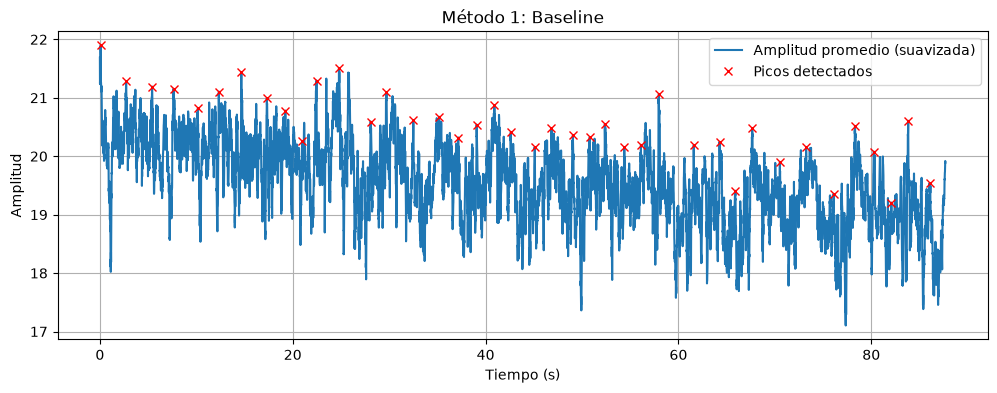

In [7]:
smoothed_mean = pd.Series(mean_amp).rolling(window=15, min_periods=1).mean().values

rpm_1, peaks_1 = rpm_from_peaks(smoothed_mean, prominence_factor=0.5)
results['1. Baseline'] = rpm_1

print(f"Picos detectados: {len(peaks_1)}")
print(f"RPM estimado (Baseline): {rpm_1:.2f}" if not np.isnan(rpm_1) else "RPM: no se detectaron suficientes picos")

plt.figure(figsize=(12, 4))
plt.plot(np.arange(len(smoothed_mean))/fs, smoothed_mean, label='Amplitud promedio (suavizada)')
plt.plot(peaks_1/fs, smoothed_mean[peaks_1], "x", color='red', label='Picos detectados')
plt.title('Método 1: Baseline')
plt.xlabel('Tiempo (s)'); plt.ylabel('Amplitud'); plt.legend(); plt.grid(True)
plt.show()


## Método 2 — Bandpass + FFT

Se aplica un filtro pasa-banda Butterworth (banda de respiración: 0.15–0.4 Hz) directamente sobre la amplitud promedio, y luego se calcula la FFT para encontrar la frecuencia dominante dentro de esa banda.

RPM estimado (Bandpass + FFT): 10.95


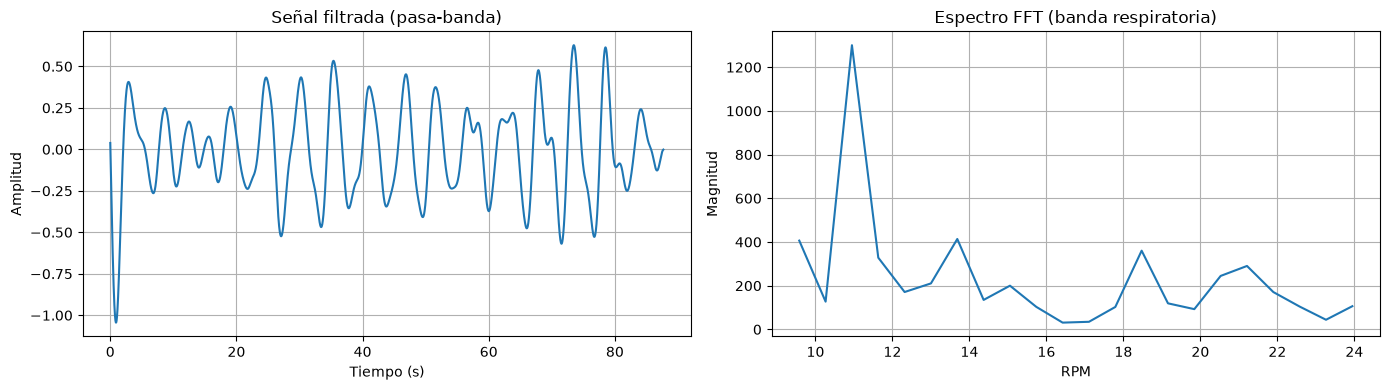

In [8]:
bp_signal_2 = bandpass(mean_amp)
rpm_2, freqs_2, spec_2 = rpm_from_fft(bp_signal_2)
results['2. Bandpass + FFT'] = rpm_2

print(f"RPM estimado (Bandpass + FFT): {rpm_2:.2f}" if not np.isnan(rpm_2) else "RPM: no se pudo estimar")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(np.arange(len(bp_signal_2))/fs, bp_signal_2)
axs[0].set_title('Señal filtrada (pasa-banda)')
axs[0].set_xlabel('Tiempo (s)'); axs[0].set_ylabel('Amplitud'); axs[0].grid(True)

band_mask = (freqs_2 >= lowcut) & (freqs_2 <= highcut)
axs[1].plot(freqs_2[band_mask]*60, spec_2[band_mask])
axs[1].set_title('Espectro FFT (banda respiratoria)')
axs[1].set_xlabel('RPM'); axs[1].set_ylabel('Magnitud'); axs[1].grid(True)
plt.tight_layout(); plt.show()


## Método 3 — PCA + FFT

Se reduce la matriz de amplitud a 1 componente principal (PC1) y se aplica FFT directamente sobre esa componente, sin pasar por un filtro pasa-banda explícito (la banda se restringe al buscar el pico en el espectro).

RPM estimado (PCA + FFT): 10.95


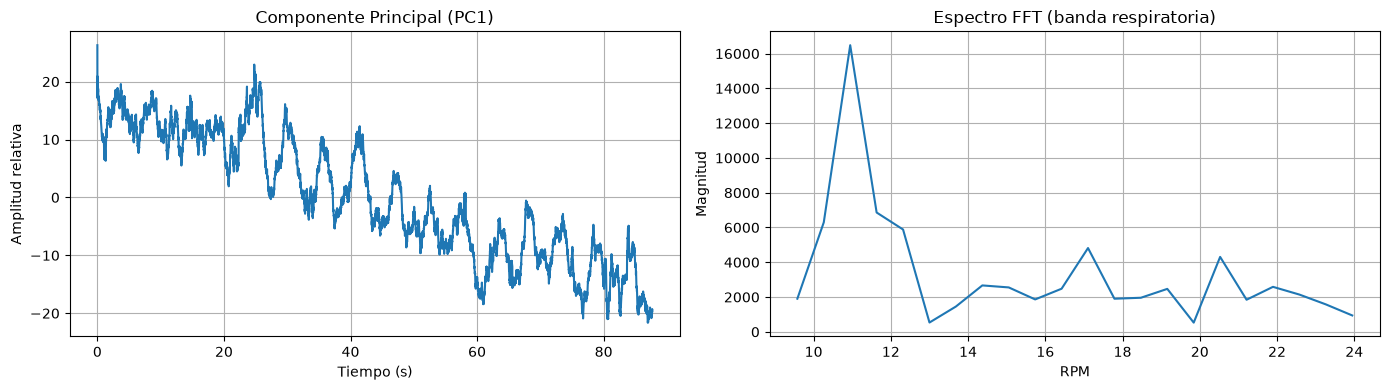

In [9]:
pc1_3 = get_pc1(amplitude)
rpm_3, freqs_3, spec_3 = rpm_from_fft(pc1_3)
results['3. PCA + FFT'] = rpm_3

print(f"RPM estimado (PCA + FFT): {rpm_3:.2f}" if not np.isnan(rpm_3) else "RPM: no se pudo estimar")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(np.arange(len(pc1_3))/fs, pc1_3)
axs[0].set_title('Componente Principal (PC1)')
axs[0].set_xlabel('Tiempo (s)'); axs[0].set_ylabel('Amplitud relativa'); axs[0].grid(True)

band_mask = (freqs_3 >= lowcut) & (freqs_3 <= highcut)
axs[1].plot(freqs_3[band_mask]*60, spec_3[band_mask])
axs[1].set_title('Espectro FFT (banda respiratoria)')
axs[1].set_xlabel('RPM'); axs[1].set_ylabel('Magnitud'); axs[1].grid(True)
plt.tight_layout(); plt.show()


## Método 4 — PCA + Peaks *(método original ya validado)*

Este es el método con el que ya se detectaban correctamente las respiraciones en el dataset: PCA sobre la amplitud suavizada, filtro pasa-banda sobre PC1, y detección de picos con prominencia dinámica.

Picos detectados: 17
RPM estimado (PCA + Peaks): 11.83


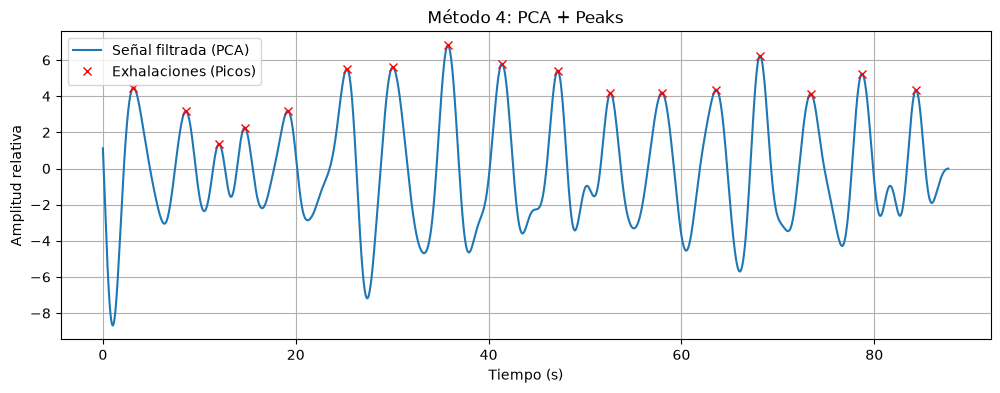

In [10]:
pc1_4 = get_pc1(amplitude)
pc1_4_bp = bandpass(pc1_4)
rpm_4, peaks_4 = rpm_from_peaks(pc1_4_bp, prominence_factor=0.8)
results['4. PCA + Peaks'] = rpm_4

print(f"Picos detectados: {len(peaks_4)}")
print(f"RPM estimado (PCA + Peaks): {rpm_4:.2f}" if not np.isnan(rpm_4) else "RPM: no se detectaron suficientes picos")

plt.figure(figsize=(12, 4))
plt.plot(np.arange(len(pc1_4_bp))/fs, pc1_4_bp, label='Señal filtrada (PCA)')
plt.plot(peaks_4/fs, pc1_4_bp[peaks_4], "x", color='red', label='Exhalaciones (Picos)')
plt.title('Método 4: PCA + Peaks')
plt.xlabel('Tiempo (s)'); plt.ylabel('Amplitud relativa'); plt.legend(); plt.grid(True)
plt.show()


## Método 5 — Hampel + FFT

Se aplica un filtro de Hampel (robusto a outliers, alternativa al pasa-banda para limpiar ruido impulsivo típico de CSI) sobre la amplitud promedio, luego un pasa-banda suave y finalmente FFT.

RPM estimado (Hampel + FFT): 10.95


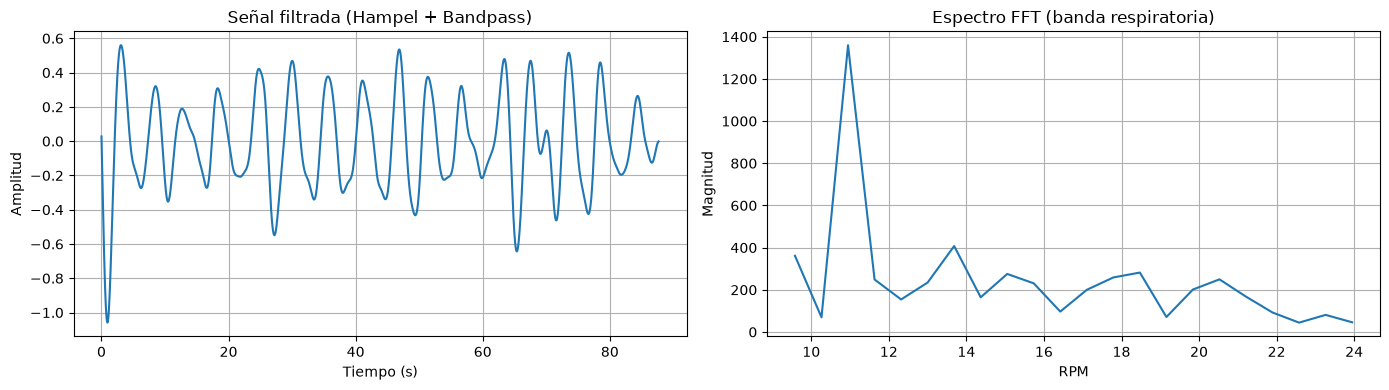

In [11]:
hampel_signal_5 = hampel_filter(mean_amp, window_size=15, n_sigmas=3)
hampel_bp_5 = bandpass(hampel_signal_5)
rpm_5, freqs_5, spec_5 = rpm_from_fft(hampel_bp_5)
results['5. Hampel + FFT'] = rpm_5

print(f"RPM estimado (Hampel + FFT): {rpm_5:.2f}" if not np.isnan(rpm_5) else "RPM: no se pudo estimar")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(np.arange(len(hampel_bp_5))/fs, hampel_bp_5)
axs[0].set_title('Señal filtrada (Hampel + Bandpass)')
axs[0].set_xlabel('Tiempo (s)'); axs[0].set_ylabel('Amplitud'); axs[0].grid(True)

band_mask = (freqs_5 >= lowcut) & (freqs_5 <= highcut)
axs[1].plot(freqs_5[band_mask]*60, spec_5[band_mask])
axs[1].set_title('Espectro FFT (banda respiratoria)')
axs[1].set_xlabel('RPM'); axs[1].set_ylabel('Magnitud'); axs[1].grid(True)
plt.tight_layout(); plt.show()


## Método 6 — Otro método: Autocorrelación (sobre PCA + Bandpass)

Como sexto método (bloque "Buscar otro" del diagrama) se implementa **autocorrelación**: busca el desfase (lag) donde la señal se parece más a sí misma dentro del rango fisiológico de respiración (6–40 RPM). Es un método complementario a FFT/picos, útil para señales cuasi-periódicas con ruido, y no depende de un umbral de prominencia como la detección de picos.

RPM estimado (Autocorrelación): 10.99


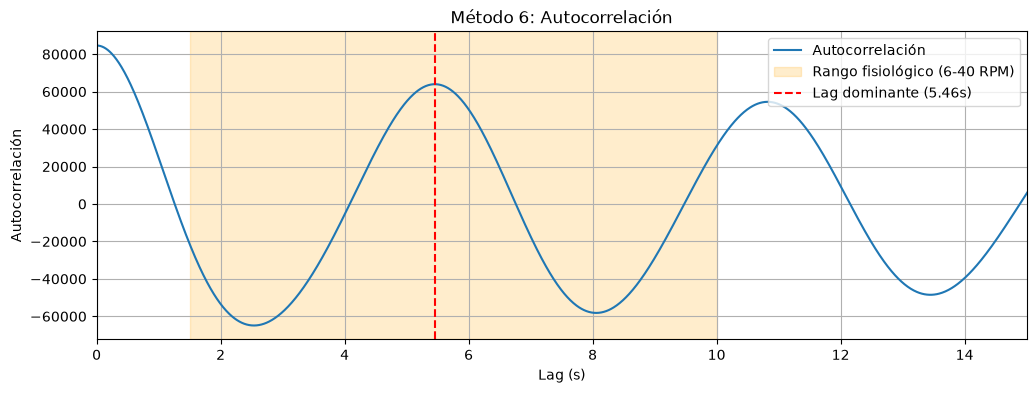

In [12]:
rpm_6, ac_6 = rpm_from_autocorr(pc1_4_bp)   # reutiliza la señal PCA + Bandpass del método 4
results['6. Autocorrelación'] = rpm_6

print(f"RPM estimado (Autocorrelación): {rpm_6:.2f}" if not np.isnan(rpm_6) else "RPM: no se pudo estimar")

lags_sec = np.arange(len(ac_6)) / fs
min_lag = int((60/max_bpm) * fs)
max_lag = int((60/min_bpm) * fs)

plt.figure(figsize=(12, 4))
plt.plot(lags_sec, ac_6, label='Autocorrelación')
plt.axvspan(min_lag/fs, max_lag/fs, color='orange', alpha=0.2, label='Rango fisiológico (6-40 RPM)')
if not np.isnan(rpm_6):
    best_lag = 60/rpm_6
    plt.axvline(best_lag, color='red', linestyle='--', label=f'Lag dominante ({best_lag:.2f}s)')
plt.title('Método 6: Autocorrelación')
plt.xlabel('Lag (s)'); plt.ylabel('Autocorrelación'); plt.legend(); plt.grid(True)
plt.xlim(0, max_lag/fs * 1.5)
plt.show()


## Comparación final de métodos

Tabla y gráfica comparativa con el RPM estimado por cada uno de los 6 métodos. Esto permite evaluar exactitud/consistencia entre métodos (por ejemplo, comparando contra un conteo manual de referencia, si se dispone de él).

In [13]:
df_results = pd.DataFrame(list(results.items()), columns=['Método', 'RPM estimado'])
df_results['RPM estimado'] = df_results['RPM estimado'].round(2)
display(df_results)


,Método,RPM estimado
0,1. Baseline,27.22
1,2. Bandpass + FFT,10.95
2,3. PCA + FFT,10.95
3,4. PCA + Peaks,11.83
4,5. Hampel + FFT,10.95
5,6. Autocorrelación,10.99


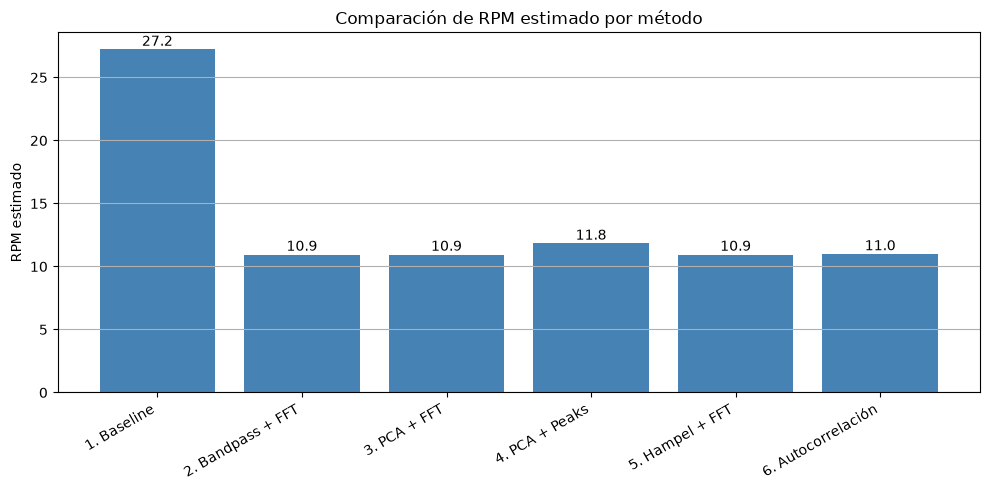

In [14]:
plt.figure(figsize=(10, 5))
bars = plt.bar(df_results['Método'], df_results['RPM estimado'], color='steelblue')
plt.ylabel('RPM estimado')
plt.title('Comparación de RPM estimado por método')
plt.xticks(rotation=30, ha='right')
plt.grid(True, axis='y')
for bar, val in zip(bars, df_results['RPM estimado']):
    if not np.isnan(val):
        plt.text(bar.get_x() + bar.get_width()/2, val + 0.3, f"{val:.1f}", ha='center')
plt.tight_layout()
plt.show()


### Notas para la comparación de exactitud

- Todos los métodos parten de la **misma matriz de amplitud** (I/Q → amplitud), por lo que las diferencias en RPM reflejan únicamente el efecto de cada técnica de procesamiento.
- Para medir **exactitud real** (no solo consistencia entre métodos) se recomienda comparar contra un conteo manual/ground truth de respiraciones durante la misma ventana de tiempo (ej. cronómetro, banda de esfuerzo torácico, o video).
- El parámetro `fs` (frecuencia de muestreo) es una estimación; si se conoce el valor real del ESP32 (o se puede derivar de timestamps reales de captura), conviene ajustarlo, ya que afecta directamente el eje de tiempo y por tanto el RPM calculado en todos los métodos.
